# Radar (Spider) Chart

**Family:** Magnitude &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Magnitude:* Compare sizes, relative or absolute (usually counts rather than rates).

## Design purpose

Plots several variables on axes radiating from a center and joins them into a polygon. Each entity's overall profile reads as a shape.

## When to use

- Compare the profile of 1–3 entities across 4–8 variables on the same scale (skills, product attributes)
- Show balance and strengths or weaknesses more than precise values

## Avoid when

- Variables use different units or scales (normalise first, or use a different chart)
- Comparing more than ~3 entities (polygons overlap; use small multiples or parallel coordinates)
- Precise comparison is required (radial distances and areas are hard to judge)

## Alternatives

- Grouped bar chart
- Parallel coordinates
- Dot plot

## Design tips

- Area grows with the square of the values, so tell readers to compare along each axis, not by area
- Keep axis order meaningful; the shape changes with order

## Example

Player ratings (0–100) on six skills for two football players.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
skills = ["Pace", "Shooting", "Passing", "Dribbling", "Defending", "Physical"]
df = pd.DataFrame({"Player A": [88, 85, 72, 86, 38, 70],
                   "Player B": [70, 62, 88, 79, 76, 82]}, index=skills)
title = "Player skill profiles"
df

,Player A,Player B
Pace,88,70
Shooting,85,62
Passing,72,88
Dribbling,86,79
Defending,38,76
Physical,70,82


### Plot

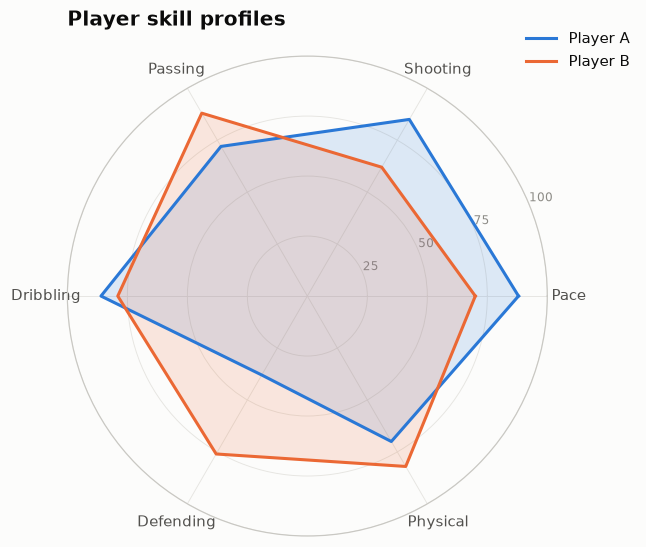

In [3]:
angles = np.linspace(0, 2 * np.pi, len(df), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
for i, col in enumerate(df.columns):
    vals = df[col].tolist() + df[col].tolist()[:1]
    ax.plot(angles, vals, color=PALETTE[i], linewidth=2, label=col)
    ax.fill(angles, vals, color=PALETTE[i], alpha=0.15)
ax.set_xticks(angles[:-1], df.index)
ax.set_ylim(0, 100)
ax.set_yticks([25, 50, 75, 100], ["25", "50", "75", "100"], color="#8c8b86", fontsize=8)
ax.spines["polar"].set_color("#c9c8c3")
ax.set_title(title, pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.2, 1.08))
fig.tight_layout()
plt.show()

## Try it with real data

**Source:** sklearn.datasets.load_wine() — chemical analysis of 178 Italian wines from 3 cultivars, bundled with scikit-learn

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
from sklearn.datasets import load_wine
w = load_wine(as_frame=True).frame
feats = {"alcohol": "Alcohol", "malic_acid": "Malic acid", "flavanoids": "Flavanoids",
         "color_intensity": "Colour intensity", "hue": "Hue", "proline": "Proline"}
means = w.groupby("target")[list(feats)].mean().rename(columns=feats)
df = (means / means.max() * 100).T.round(0)          # % of the highest cultivar mean
df.columns = [f"Cultivar {i + 1}" for i in df.columns]
title = "Wine cultivars (% of highest mean)"
df

,Cultivar 1,Cultivar 2,Cultivar 3
Alcohol,100.0,89.0,96.0
Malic acid,60.0,58.0,100.0
Flavanoids,100.0,70.0,26.0
Colour intensity,75.0,42.0,100.0
Hue,100.0,99.0,64.0
Proline,100.0,47.0,56.0


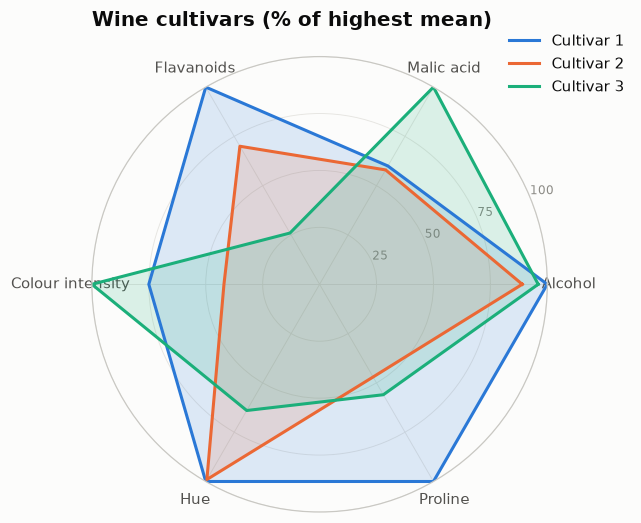

In [5]:
angles = np.linspace(0, 2 * np.pi, len(df), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
for i, col in enumerate(df.columns):
    vals = df[col].tolist() + df[col].tolist()[:1]
    ax.plot(angles, vals, color=PALETTE[i], linewidth=2, label=col)
    ax.fill(angles, vals, color=PALETTE[i], alpha=0.15)
ax.set_xticks(angles[:-1], df.index)
ax.set_ylim(0, 100)
ax.set_yticks([25, 50, 75, 100], ["25", "50", "75", "100"], color="#8c8b86", fontsize=8)
ax.spines["polar"].set_color("#c9c8c3")
ax.set_title(title, pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.2, 1.08))
fig.tight_layout()
plt.show()

---
Standalone script: [`radar_chart.py`](radar_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)